# Boolean Gates Extensions

NicDeclic  
2026-11-04

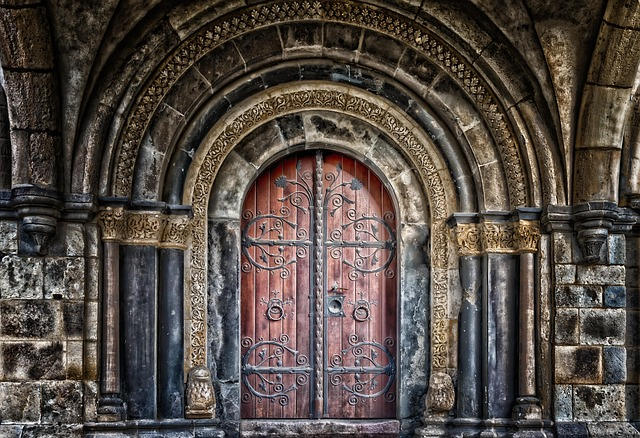

> *“Strength lies not in what resists… but in what persists.”*  
> — **Professor Alvin**

------------------------------------------------------------------------

In [1]:
import sys
if 'google.colab' in sys.modules:
    # 1. Download qmc.py from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/qmc.py
    
    # 2. Download requirements.txt from GitHub
    !wget -q https://raw.githubusercontent.com/nicdeclic/quantum-molecular-computing/main/requirements.txt

    # 3. Install dependencies
    !pip install -q -r requirements.txt

sys.path.insert(0, "../../src") # Select root directory
from qmc import * # QMC library

%reload_ext autoreload
%autoreload 2

------------------------------------------------------------------------

We previously revisited fundamental logic gates in [“A Refresher on
Boolean Logic”](../../posts/boolean-logic/index.html). However, we have
now established that within the framework of **Conjugated Carbon
Computing (CCC)**, our computational substrate operates on **protobits**
rather than classical binary bits.

At their baseline, these boolean gates rely on the exact same transition
matrices introduced earlier. Yet, because they are embodied in real
quantum-molecular networks, they natively handle continuous probability
distributions as well as genuine quantum phenomena such as coherent
**superposition** and **entanglement**.

This shift unlocks a rich landscape of entirely non-classical behaviors.
Let us explore some of these exotic properties:

------------------------------------------------------------------------

## Full I/O Inversion (Reverse Computing)

Because our molecular transition matrices are bidirectional, it is now
possible to completely flip the roles of inputs and outputs.

### Inverted AND Gate

In this reverse configuration, we drive the circuit from the single
terminal $C$ on the left, and observe the resulting quantum
superposition across terminals $A$ and $B$ on the right:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Place the 2-input AND gate oriented to the LEFT
    and_gate = d.add(logic.And().left())

    # 2. Input line on the left (connected to the single terminal, formerly Output C)
    d.add(elm.Line().left(1.5).at(and_gate.out).label("C", loc="left"))

    # 3. Output lines on the right (formerly Inputs A and B)
    d.add(elm.Line().right(1.5).at(and_gate.in1).label("B", loc="right"))
    d.add(elm.Line().right(1.5).at(and_gate.in2).label("A", loc="right"))


display_inline("C", r"\cdot", r"And^{-1}", "=", "(A", r"\otimes", "B)")

display_inline(r"And^{-1}", "=", r"\{And^{T}\}", "=", and_rev_q.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span
class="math display"><em>C</em> ⋅ <em>A</em><em>n</em><em>d</em><sup>−1</sup> = (<em>A</em> ⊗ <em>B</em>)</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ And^{-1} = \{And^{T}\}
=  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline
\text{``0''} &amp; 0.33 &amp; 0.33 &amp; 0.33 &amp; 0 \\ \text{``1''}
&amp; 0 &amp; 0 &amp; 0 &amp; 1 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

- When $C = 0$, outputs $A$ and $B$ can be “00”, “01” or “10” with equal
  probability.  
- When $C = 1$, outputs $A$ and $B$ can only be “11”.

### Inverted OR Gate

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Place the 2-input OR gate oriented to the LEFT
    or_gate = d.add(logic.Or().left())

    # 2. Input line on the left (connected to the single terminal, formerly Output C)
    d.add(elm.Line().left(1.5).at(or_gate.out).label("C", loc="left"))

    # 3. Output lines on the right (formerly Inputs A and B)
    d.add(elm.Line().right(1.5).at(or_gate.in1).label("B", loc="right"))
    d.add(elm.Line().right(1.5).at(or_gate.in2).label("A", loc="right"))


display_inline("C", r"\cdot", r"Or^{-1}", "=", "(A", r"\otimes", "B)")

display_inline(r"Or^{-1}", "=", r"\{Or^{T}\}", "=", or_rev_q.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span
class="math display"><em>C</em> ⋅ <em>O</em><em>r</em><sup>−1</sup> = (<em>A</em> ⊗ <em>B</em>)</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ Or^{-1} = \{Or^{T}\}
=  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline
\text{``0''} &amp; 1 &amp; 0 &amp; 0 &amp; 0 \\ \text{``1''} &amp; 0
&amp; 0.33 &amp; 0.33 &amp; 0.33 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

### Inverted XOR Gate

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Place the 2-input XOR gate oriented to the LEFT
    xor_gate = d.add(logic.Xor().left())

    # 2. Input line on the left (connected to the single terminal, formerly Output C)
    d.add(elm.Line().left(1.5).at(xor_gate.out).label("C", loc="left"))

    # 3. Output lines on the right (formerly Inputs A and B)
    d.add(elm.Line().right(1.5).at(xor_gate.in1).label("B", loc="right"))
    d.add(elm.Line().right(1.5).at(xor_gate.in2).label("A", loc="right"))


display_inline("C", r"\cdot", r"Xor^{-1}", "=", "(A", r"\otimes", "B)")

display_inline(r"Xor^{-1}", "=", r"\{Xor^{T}\}", "=", xor_rev_q.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span
class="math display"><em>C</em> ⋅ <em>X</em><em>o</em><em>r</em><sup>−1</sup> = (<em>A</em> ⊗ <em>B</em>)</span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ Xor^{-1} = \{Xor^{T}\}
=  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline
\text{``0''} &amp; 0.5 &amp; 0 &amp; 0 &amp; 0.5 \\ \text{``1''} &amp; 0
&amp; 0.5 &amp; 0.5 &amp; 0 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

------------------------------------------------------------------------

## Back-to-Back Cascades: The Non-Commutative Trap

When chaining a logic gate directly into its physical mirror image (its
Bayesian inverse), intuition might tempt us to assume that the two
transformations always cancel out to form an **Identity operator**:

$$M \cdot M^{-1} \stackrel{?}{=} I$$

In molecular computing, **this naive assumption frequently fails.**

### Case 1: The 2-Input / 2-Output Cascade ($\text{And} \cdot \text{And}^{-1} \neq I$)

Here, two input channels ($A, B$) are merged through an $\text{And}$
gate ($4 \times 2$), and the resulting single intermediate wire is
immediately expanded back through an inverted $\text{And}^{-1}$ gate
($2 \times 4$):

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Forward AND Gate (pointing right)
    gate_fwd = d.add(logic.And().right().label("And", loc="top"))
    d.add(elm.Line().left(1.5).at(gate_fwd.in1).label("A", loc="left"))
    d.add(elm.Line().left(1.5).at(gate_fwd.in2).label("B", loc="left"))

    # 2. Reverse AND Gate (pointing left, positioned to the right)
    gate_rev = d.add(
        logic.And().left().at((gate_fwd.out[0] + 3.0, gate_fwd.out[1]))
        .label(r"$\text{And}^{-1}$", loc="top")
    )

    # Connecting intermediate wire between the two single pins
    d.add(elm.Line().at(gate_fwd.out).to(gate_rev.out))

    # Output lines emerging on the far right
    d.add(elm.Line().right(1.5).at(gate_rev.in1).label("B'", loc="right"))
    d.add(elm.Line().right(1.5).at(gate_rev.in2).label("A'", loc="right"))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

In this configuration, **$\text{And} \cdot \text{And}^{-1}$ does NOT
equal the identity ($I_4$).**

``` python
display_inline(r"{And}", r"\cdot", r"{And}^{-1}", "=", (and_q @ and_rev_q).to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ {And} \cdot {And}^{-1}
=  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline
\text{``00''} &amp; 0.33 &amp; 0.33 &amp; 0.33 &amp; 0 \\ \text{``01''}
&amp; 0.33 &amp; 0.33 &amp; 0.33 &amp; 0 \\ \text{``10''} &amp; 0.33
&amp; 0.33 &amp; 0.33 &amp; 0 \\ \text{``11''} &amp; 0 &amp; 0 &amp; 0
&amp; 1 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

### Case 2: The 1-Input / 1-Output Cascade ($\text{And}^{-1} \cdot \text{And} = I$)

Now, let us reverse the sequence: we begin with a single input channel
$C$, branch it open through an inverted $\text{And}^{-1}$ gate
($2 \times 4$), and immediately recombine the dual branches through a
forward $\text{And}$ gate ($4 \times 2$):

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Reverse AND Gate (expanding 1 wire into 2)
    gate_rev = d.add(logic.And().left().label(r"$\text{And}^{-1}$", loc="top"))
    d.add(elm.Line().left(1.5).at(gate_rev.out).label("C", loc="left"))

    # 2. Forward AND Gate (recombining 2 wires into 1)
    gate_fwd = d.add(
        logic.And().right().at((gate_rev.in1[0] + 3.0, (gate_rev.in1[1] + gate_rev.in2[1]) / 2.0))
        .label("And", loc="top")
    )

    # Connecting the two parallel intermediate lines
    d.add(elm.Line().at(gate_rev.in1).to(gate_fwd.in2))
    d.add(elm.Line().at(gate_rev.in2).to(gate_fwd.in1))

    # Final single output wire on the far right
    d.add(elm.Line().right(1.5).at(gate_fwd.out).label("C'", loc="right"))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

In this configuration, **$\text{AND}^{-1} \cdot \text{AND}$ strictly
equals the $2 \times 2$ Identity matrix ($I_2$)!**

``` python
display_inline(r"{And}^{-1}", r"\cdot", r"{And}", "=", (and_rev_q @ and_q).to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ {And}^{-1} \cdot {And}
=  \begin{array}{r|cc|} \text{} &amp; \text{``0''} &amp; \text{``1''}
\\  \hline \text{``0''} &amp; 1 &amp; 0 \\ \text{``1''} &amp; 0 &amp; 1
\\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Transition matrices can contract or expand the state space dimension,
the order of composition strictly dictates whether information is
conserved or permanently degraded into probabilistic mixing.

------------------------------------------------------------------------

## Random Noise as a Computational Resource

In classical digital electronics, randomness is considered an
enemy—unwanted thermal noise that must be filtered out. In **Conjugated
Carbon Computing (CCC)**, however, stochastic states can be deliberately
injected as an active computational resource.

A particularly powerful primitive is the **balanced random state (fair
coin)**:

``` python
display_inline(r"{Random}", "=", (random).to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ {Random} =  \begin{array}{r|cc|}
\text{} &amp; \text{``0''} &amp; \text{``1''} \\  \hline ~ &amp; 0.5
&amp; 0.5 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

### 1. The Random-And Gate

Feeding a balanced random state into one port of an $\text{And}$ gate
suppresses and biases the transmission of signal $A$:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    gate = d.add(logic.And().right())
    d.add(elm.Line().left(1.8).at(gate.in1).label("A", loc="left"))
    d.add(elm.Line().left(0.5).at(gate.in2).label(r"$\text{Random}$", loc="left"))
    d.add(elm.Line().right(1.5).at(gate.out).label("B", loc="right"))

random_and = ((identity ^ random) @ and_q).normalize()

display_inline(r"\text{Random-And}", "=", r"\Big\{", "(", "Identity", r"\otimes", "Random", ")", r"\cdot", "And", r"\Big\}", "=", random_and.to_katex(show_labels=True))    
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \text{Random-And} = \Big\{ ( Identity
\otimes Random ) \cdot And \Big\} =  \begin{array}{r|cc|} \text{} &amp;
\text{``0''} &amp; \text{``1''} \\  \hline \text{``0''} &amp; 1 &amp; 0
\\ \text{``1''} &amp; 0.5 &amp; 0.5 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

- When $A = 0$, output $B$ is deterministically clamped to “0”
  ($[1 \quad 0]$).  
- When $A = 1$, output $B$ directly inherits the random distribution
  $[1/2 \quad 1/2]$.

When one input of a two-input logic gate is held at this balanced
stochastic state, the gate ceases to behave like a deterministic switch.
Instead, it transforms into a **tunable probabilistic filter**,
modulating the remaining signal $A$ into output $B$.

### 2. The Random-Or Gate

Feeding a balanced random state into an $\text{Or}$ gate creates a
similar dual behavior:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    gate = d.add(logic.Or().right())
    d.add(elm.Line().left(1.8).at(gate.in1).label("A", loc="left"))
    d.add(elm.Line().left(0.5).at(gate.in2).label(r"$\text{Random}$", loc="left"))
    d.add(elm.Line().right(1.5).at(gate.out).label("B", loc="right"))

random_or = ((identity ^ random) @ or_q).normalize()

display_inline(r"\text{Random-Or}", "=", r"\Big\{", "(", "Identity", r"\otimes", "Random", ")", r"\cdot", "Or", r"\Big\}","=", random_or.to_katex(show_labels=True))   
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \text{Random-Or} = \Big\{ ( Identity
\otimes Random ) \cdot Or \Big\} =  \begin{array}{r|cc|} \text{} &amp;
\text{``0''} &amp; \text{``1''} \\  \hline \text{``0''} &amp; 0.5 &amp;
0.5 \\ \text{``1''} &amp; 0 &amp; 1 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

- When $A = 0$, output $B$ directly inherits the random distribution
  $[1/2 \quad 1/2]$.  
- When $A = 1$, output $B$ is deterministically clamped to “1”
  ($[0 \quad 1]$).

### 3. The Random-Xor Gate: The Quantum Jammer / Depolarizer

Feeding a balanced random state into a $\text{Xor}$ gate produces a
striking physical effect:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    gate = d.add(logic.Xor().right())
    d.add(elm.Line().left(1.8).at(gate.in1).label("A", loc="left"))
    d.add(elm.Line().left(0.5).at(gate.in2).label(r"$\text{Random}$", loc="left"))
    d.add(elm.Line().right(1.5).at(gate.out).label("B", loc="right"))

random_xor = ((identity ^ random) @ xor_q).normalize()

display_inline(r"\text{Random-Xor}", "=", r"\Big\{", "(", "Identity", r"\otimes", "Random", ")", r"\cdot", "Xor", r"\Big\}","=", random_xor.to_katex(show_labels=True))     
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \text{Random-Xor} = \Big\{ ( Identity
\otimes Random ) \cdot Xor \Big\} =  \begin{array}{r|cc|} \text{} &amp;
\text{``0''} &amp; \text{``1''} \\  \hline \text{``0''} &amp; 0.5 &amp;
0.5 \\ \text{``1''} &amp; 0.5 &amp; 0.5 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Regardless of whether input $A$ is $0$ or $1$, the $\text{Xor}$
transformation completely scrambles the state.

The Random-Xor gate acts as a **perfect hardware depolarizer (entropy
injector)**—completely erasing the input signal and replacing it with
maximal entropy.

------------------------------------------------------------------------

## Partial I/O Inversion (Pin Flipping)

In addition to full forward or backward execution, our molecular
architecture permits a far more surgical operation: **inverting a single
individual input or output pin.**

Because a chemical bond is fundamentally an undirected degree of
freedom, we can mathematically “fold” a terminal wire backward using our
primitive topological operators (such as the Identity, Open, Close, and
Bayesian transposition).

This allows us to reconfigure a multi-pin logic component on the fly
without resynthesizing the underlying molecular skeleton.

### 1. Inverting an Input into an Output

Consider a standard 2-input AND gate. What happens if we keep input $A$
on the left, but rewire the bottom input pin $B$ so that it folds back
and emerges as an **output** on the right alongside $C$?

The component morphs from a 2-in / 1-out gate into a **1-in / 2-out
functional beam-splitter**:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Place the standard AND gate
    and_gate = d.add(logic.And().right())

    # 2. Input A on the left
    d.add(elm.Line().left(2.0).at(and_gate.in1).label("A", loc="left"))

    # 3. Output C on the right
    d.add(elm.Line().right(2.0).at(and_gate.out).label("C", loc="right"))

    # 4. Input B rewired/folded backward into an output pin on the right (B)
    d.add(elm.Line().left(0.8).at(and_gate.in2))
    d.add(elm.Line().down(1.5))
    d.add(elm.Line().right(4.2))
    d.add(elm.Line().right(0.5).label("B", loc="right"))

and1_2 = ((identity ^ open) @ (and_q ^ identity)).normalize()

display_inline(r"\text{And-1-2}", "=", r"\Big\{", "(", "Identity",  r"\otimes", "Open", ")", r"\cdot", "(", "And", r"\otimes",  "Identity", ")", r"\Big\}", "=", and1_2.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \text{And-1-2} = \Big\{ ( Identity
\otimes Open ) \cdot ( And \otimes Identity ) \Big\}
=  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline
\text{``0''} &amp; 0.5 &amp; 0.5 &amp; 0 &amp; 0 \\ \text{``1''} &amp;
0.5 &amp; 0 &amp; 0 &amp; 0.5 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

In this mode, holding input $A$ at state `"1"` forces output $B$ to
match output $C$ identically, effectively implementing a conditional
identity channel.

### 2. Inverting the Output into an Input of an Inverted Gate

Conversely, consider an inverted gate where an output wire on the right
is folded backward to receive signals as an **input** on the left:

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Place an inverted AND gate (pointing left)
    and_rev = d.add(logic.And().left())

    # 2. Input C on the far left
    d.add(elm.Line().left(2.0).at(and_rev.out).label("C", loc="left"))

    # 3. Output A on the far right
    d.add(elm.Line().right(2.0).at(and_rev.in2).label("A", loc="right"))

    # 4. Output B folded backward into an input pin on the left (B)
    d.add(elm.Line().right(0.8).at(and_rev.in1))
    d.add(elm.Line().down(1.5))
    d.add(elm.Line().left(4.2))
    d.add(elm.Line().left(0.5).label("B", loc="left"))

and_rev_2_1 = ((and_rev_q ^ identity) @ (identity ^ close)).normalize()

display_inline(r"\text{And-Rev-1-2}", "=", r"\Big\{", "(", r"{And}^{-1}",  r"\otimes", "Identity", ")", r"\cdot", "(", "Identity", r"\otimes",  "Close", ")", r"\Big\}", "=", and_rev_2_1.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ \text{And-Rev-1-2} = \Big\{ (
{And}^{-1} \otimes Identity ) \cdot ( Identity \otimes Close ) \Big\}
=  \begin{array}{r|cc|} \text{} &amp; \text{``0''} &amp; \text{``1''}
\\  \hline \text{``00''} &amp; 0.5 &amp; 0.5 \\ \text{``01''} &amp; 1
&amp; 0 \\ \text{``10''} &amp; 0 &amp; 0 \\ \text{``11''} &amp; 0 &amp;
1 \\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

### The Power of Topological Rewiring

This partial inversion demonstrates a core principle of Conjugated
Carbon Computing: **functional directionality is entirely dynamic.**

- A single physical 3-terminal carbon structure is not permanently
  etched as a “gate”: it can operate either as a **$2 \rightarrow 1$
  logical combiner** (forward) or as a **$1 \rightarrow 2$ conditional
  splitter** (partially inverted).  
- We do not replace physical hardware to change the nature of the
  operation; we simply reassign which boundary bonds we clamp as inputs
  and which ones we leave free to oscillate as outputs.

------------------------------------------------------------------------

## Correlated Inputs & The Kronecker Product Trap

A common mathematical trap when modeling composite inputs is naively
using the Kronecker tensor product ($A \otimes B$) when the signals are
**physically correlated**.

Consider a classic test case: a 2-input AND gate where both input pins
are tied directly to the **very same input wire $A$** :

``` python
with schemdraw.Drawing() as d:
    d.config(fontsize=12, unit=2.5)

    # 1. Place the 2-input AND gate
    and_gate = d.add(logic.And().right())

    # 2. Output wire B
    d.add(elm.Line().right(1.0).at(and_gate.out).label("B", loc="right"))

    # 3. Input wire A branching into both in1 and in2
    in_mid_y = (and_gate.in1[1] + and_gate.in2[1]) / 2.0
    input_A = d.add(elm.Line().right(1.0).at((and_gate.in1[0] - 1.5, in_mid_y)).label("A", loc="left"))
    
    # Route to top input (in1)
    d.add(elm.Wire("-|").at(input_A.end).to(and_gate.in1))

    # Route to bottom input (in2)
    d.add(elm.Wire("-|").at(input_A.end).to(and_gate.in2))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: center;"><div width="100.0%"
data-layout-align="center">
<p></p>
</div></td>
</tr>
</tbody>
</table>

### Where the Math Breaks Down

If input $A$ is a deterministic boolean value (`"0"` or `"1"`), no issue
arises:  
\* If $A = 0$, both pins see $0$, and the output $B$ is $0$.  
\* If $A = 1$, both pins see $1$, and the output $B$ is $1$.  
The circuit behaves strictly as an Identity buffer ($B = A$).

**However, watch what happens when input $A$ carries a probabilistic
state (such as our “fair coin” Random bit: $[0.5 \quad 0.5]$):**

If one naively computes the joint input using the tensor product:

``` python
random_squared = random ^ random

display_inline("(", "A", r"\otimes", "A", ")", "=", "(", "Random", r"\otimes", "Random", ")", "=", random_squared.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ ( A \otimes A ) = ( Random \otimes
Random ) =  \begin{array}{r|cccc|} \text{} &amp; \text{``00''} &amp;
\text{``01''} &amp; \text{``10''} &amp; \text{``11''} \\  \hline ~ &amp;
0.25 &amp; 0.25 &amp; 0.25 &amp; 0.25 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

This multiplication fails catastrophically!

The Kronecker product assumes **statistical independence**: it assigns a
$25\%$ probability to the state `"01"` and a $25\%$ probability to
`"10"`. But this is a physical impossibility: because both pins are
physically wired to the identical bond $A$, they can **never** disagree!

The states `"01"` and `"10"` make no physical sense on a shared wire.

### The Solution: The Split Operator (Coherent Fan-Out)

To duplicate a state while preserving $100\%$ correlation, we must not
compute an independent tensor product. Instead, we must route the single
wire through a **Split transition matrix**:

The Split operator explicitly maps:  
\* `"0"` $\longrightarrow$ `"00"`  
\* `"1"` $\longrightarrow$ `"11"`

``` python
display_inline("Split", "=", split.to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ Split =  \begin{array}{r|cccc|} \text{}
&amp; \text{``00''} &amp; \text{``01''} &amp; \text{``10''} &amp;
\text{``11''} \\  \hline \text{``0''} &amp; 1 &amp; 0 &amp; 0 &amp; 0 \\
\text{``1''} &amp; 0 &amp; 0 &amp; 0 &amp; 1 \\  \hline
\end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

When input $A$ passes through the Split matrix, it produces the true
correlated joint state:

``` python
display_inline("A", r"\cdot", "Split", "=", (random @ split).to_katex(show_labels=True))
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$ A \cdot Split =  \begin{array}{r|cccc|}
\text{} &amp; \text{``00''} &amp; \text{``01''} &amp; \text{``10''}
&amp; \text{``11''} \\  \hline ~ &amp; 0.5 &amp; 0 &amp; 0 &amp; 0.5
\\  \hline \end{array}  $$</span></p>
</div></td>
</tr>
</tbody>
</table>

Now, cascading this properly into the AND gate restores mathematical and
physical truth:

``` python
display_inline("(", "A", r"\cdot", "Split", ")", r"\cdot", "And", "=", "B")

display_inline((random @ split).to_katex(), r"\cdot", and_q.to_katex(), "=", ((random @ split) @ and_q).to_katex(), "=", "A")
```

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span
class="math display">(<em>A</em> ⋅ <em>S</em><em>p</em><em>l</em><em>i</em><em>t</em>) ⋅ <em>A</em><em>n</em><em>d</em> = <em>B</em></span></p>
</div></td>
</tr>
</tbody>
</table>

<table>
<colgroup>
<col style="width: 100%" />
</colgroup>
<tbody>
<tr>
<td style="text-align: left;"><div width="100.0%"
data-layout-align="left">
<p><span class="math display">$$  \begin{array}{|cccc|}  \hline 0.5
&amp; 0 &amp; 0 &amp; 0.5 \\  \hline
\end{array}  \cdot  \begin{array}{|cc|}  \hline 1 &amp; 0 \\ 1 &amp; 0
\\ 1 &amp; 0 \\ 0 &amp; 1 \\  \hline
\end{array}  =  \begin{array}{|cc|}  \hline 0.5 &amp; 0.5 \\  \hline
\end{array}  = A $$</span></p>
</div></td>
</tr>
</tbody>
</table>

The identity $B = A$ is preserved, the impossible states are purged, and
the correlation is maintained with mathematical perfection.

------------------------------------------------------------------------

👉 **Next chapter :**  
**[“Qubit Emulation”](../../posts/qubit-emulation/index.html)**